In [1]:
cd /home/lihaoxing/loop_apa

/home/lihaoxing/loop_apa


In [9]:
import cooler
import numpy as np
import pandas as pd
from tqdm import tqdm

cool_file = "IVF_10000.cool"
loop_file = "IVF_2C.subsample.bedpe"
window = 10

clr = cooler.Cooler(cool_file)
bins = clr.bins()[:]
bin_size = clr.binsize

loops = pd.read_csv(loop_file, sep="\t", header=None)

# ======================
# ✔ 正确 chrom offset
# ======================
chrom_offset = {}
for chrom in clr.chromnames:
    chrom_offset[chrom] = bins.index[bins["chrom"] == chrom][0]

# ======================
# matrix
# ======================
mat = clr.matrix(balance=False)[:]

size = 2 * window + 1
apa = np.zeros((size, size))
count = 0

# ======================
# main loop
# ======================
for _, row in tqdm(loops.iterrows(), total=len(loops)):

    chrom1 = str(row[0])
    chrom2 = str(row[3])

    # skip chr mismatch
    if chrom1 != chrom2:
        continue

    if chrom1 not in chrom_offset:
        continue

    start1 = int(row[1])
    start2 = int(row[4])

    # ======================
    # bin mapping
    # ======================
    bin1 = chrom_offset[chrom1] + start1 // bin_size
    bin2 = chrom_offset[chrom2] + start2 // bin_size

    i0, i1 = bin1 - window, bin1 + window + 1
    j0, j1 = bin2 - window, bin2 + window + 1

    if i0 < 0 or j0 < 0 or i1 > mat.shape[0] or j1 > mat.shape[1]:
        continue

    sub = mat[i0:i1, j0:j1]

    if sub.shape == (2 * window + 1, 2 * window + 1):
        apa += sub
        count += 1

if count == 0:
    raise ValueError("Still 0 → genome build mismatch or bin size mismatch")

apa /= count

print("Used loops:", count)

100%|██████████| 20000/20000 [00:01<00:00, 14154.51it/s]

Used loops: 19989


In [17]:
import pandas as pd
import numpy as np
import glob
import os

# 固定随机种子（可复现）
np.random.seed(42)

arcs_files = glob.glob("*.arcs")

for af in arcs_files:
    print(f"Processing {af}")

    df = pd.read_csv(af, sep="\t", header=None)
    df.columns = ["chr1", "start1", "end1", "chr2", "start2", "end2"]

    n = len(df)

    # =========================
    # 生成严格一半索引
    # =========================
    perm = np.random.permutation(n)
    half = n // 2

    cluster = np.zeros(n, dtype=int)
    cluster[perm[half:]] = 1

    df["cluster"] = cluster

    base = af.replace(".arcs", "")

    # =========================
    # 输出
    # =========================
    for c in [0, 1]:
        sub = df[df["cluster"] == c].drop(columns=["cluster"])
        out = f"{base}_cluster{c}.arcs"
        sub.to_csv(out, sep="\t", header=False, index=False)

        print(f"  {out}: n={len(sub)}")

Processing PA_2C_norm_cells_no_duplicates.arcs
  PA_2C_norm_cells_no_duplicates_cluster0.arcs: n=93369
  PA_2C_norm_cells_no_duplicates_cluster1.arcs: n=93370
Processing IVF_2C_norm_cells_no_duplicates.arcs
  IVF_2C_norm_cells_no_duplicates_cluster0.arcs: n=104425
  IVF_2C_norm_cells_no_duplicates_cluster1.arcs: n=104425
Processing IVF_4C_norm_cells_no_duplicates.arcs
  IVF_4C_norm_cells_no_duplicates_cluster0.arcs: n=164109
  IVF_4C_norm_cells_no_duplicates_cluster1.arcs: n=164109
Processing PA_4C_norm_cells_no_duplicates.arcs
  PA_4C_norm_cells_no_duplicates_cluster0.arcs: n=109718
  PA_4C_norm_cells_no_duplicates_cluster1.arcs: n=109719
Processing PA_2C_C1_norm_cells_no_duplicates.arcs
  PA_2C_C1_norm_cells_no_duplicates_cluster0.arcs: n=62687
  PA_2C_C1_norm_cells_no_duplicates_cluster1.arcs: n=62687
Processing PA_2C_C2_norm_cells_no_duplicates.arcs
  PA_2C_C2_norm_cells_no_duplicates_cluster0.arcs: n=45576
  PA_2C_C2_norm_cells_no_duplicates_cluster1.arcs: n=45577
Processing IVF_2

In [18]:
import pandas as pd
import numpy as np
import glob
import os

np.random.seed(42)

files = glob.glob("*bedpe")

for f in files:
    print(f"Processing {f}")

    df = pd.read_csv(f, sep="\t", header=None)

    n = len(df)

    # =========================
    # 10% downsampling
    # =========================
    keep_n = max(1, int(n * 0.1))
    keep_idx = np.random.choice(df.index, size=keep_n, replace=False)

    df_sub = df.loc[keep_idx].copy()

    out = f.replace(".bedpe", "_down10.bedpe")

    df_sub.to_csv(out, sep="\t", header=False, index=False)

    print(f"  {out}: {len(df_sub)} / {n}")

Processing IVF_2C_norm_cells_no_duplicates.arcs.bedpe
  IVF_2C_norm_cells_no_duplicates.arcs_down10.bedpe: 20885 / 208850
Processing IVF_4C_norm_cells_no_duplicates.arcs.bedpe
  IVF_4C_norm_cells_no_duplicates.arcs_down10.bedpe: 32821 / 328218
Processing PA_2C_norm_cells_no_duplicates.arcs.bedpe
  PA_2C_norm_cells_no_duplicates.arcs_down10.bedpe: 18673 / 186739
Processing PA_4C_norm_cells_no_duplicates.arcs.bedpe
  PA_4C_norm_cells_no_duplicates.arcs_down10.bedpe: 21943 / 219437
Processing IVF_2C.subsample.bedpe
  IVF_2C.subsample_down10.bedpe: 2000 / 20000
Processing IVF_4C.subsample.bedpe
  IVF_4C.subsample_down10.bedpe: 3000 / 30000
Processing PA_2C.subsample.bedpe
  PA_2C.subsample_down10.bedpe: 1800 / 18000
Processing PA_4C.subsample.bedpe
  PA_4C.subsample_down10.bedpe: 2200 / 22000
Processing IVF_2C_C1_norm_cells_no_duplicates.arcs.bedpe
  IVF_2C_C1_norm_cells_no_duplicates.arcs_down10.bedpe: 12700 / 127008
Processing IVF_2C_C1_norm_cells_no_duplicates_cluster0.arcs.bedpe
  IVF_

In [2]:
cd /home/lihaoxing/loop_apa/4c/4c

/home/lihaoxing/loop_apa/4c/4c


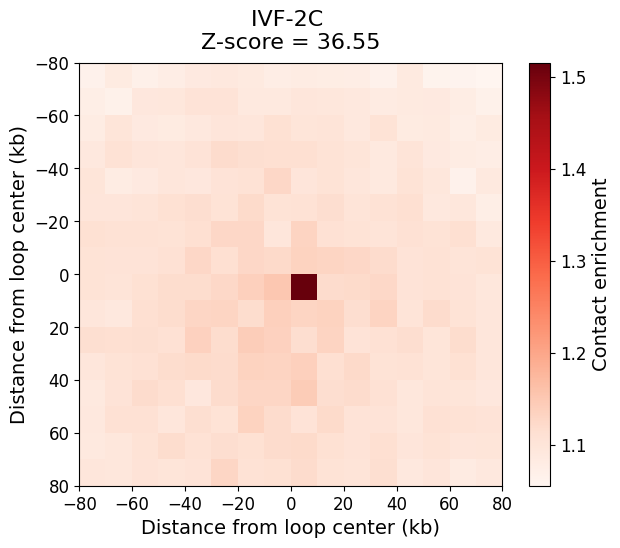

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_norm_cells_no_duplicates.arcs.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C \nZ-score = {z:.2f}",
    pad=10
)


plt.tight_layout()
plt.savefig('IVF_2C_APA_with_zscore.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

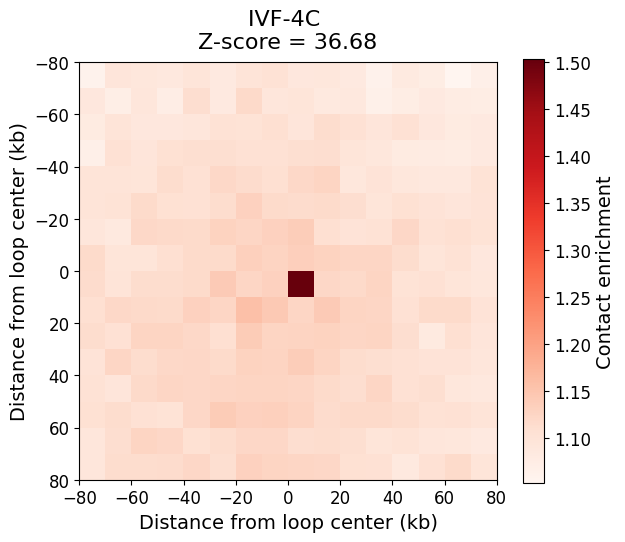

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_norm_cells_no_duplicates.arcs.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C \nZ-score = {z:.2f}",
    pad=10
)

plt.tight_layout()
plt.savefig('IVF_4C_APA_with_zscore.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

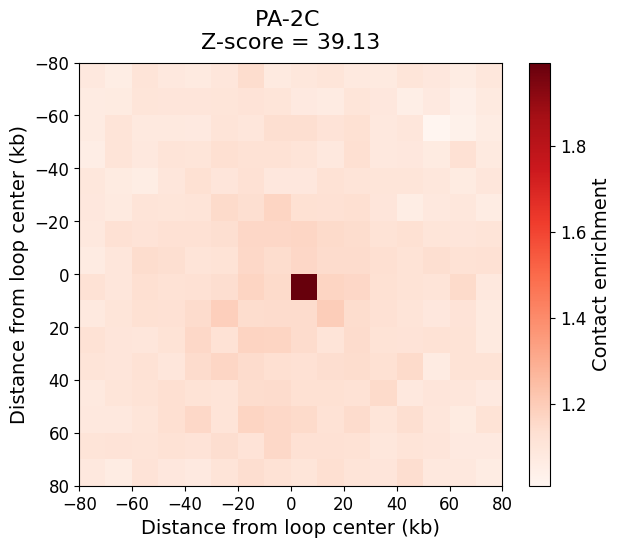

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_norm_cells_no_duplicates.arcs.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C \nZ-score = {z:.2f}",
    pad=10
)


# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_APA_with_zscore.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

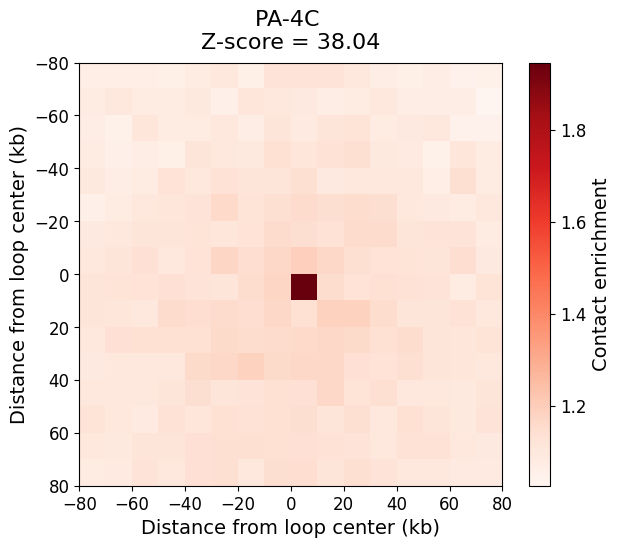

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_norm_cells_no_duplicates.arcs.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C \nZ-score = {z:.2f}",
    pad=10
)

plt.tight_layout()
plt.savefig('PA_4C_APA_with_zscore.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [54]:
cd /home/lihaoxing/loop_apa/4c

/home/lihaoxing/loop_apa


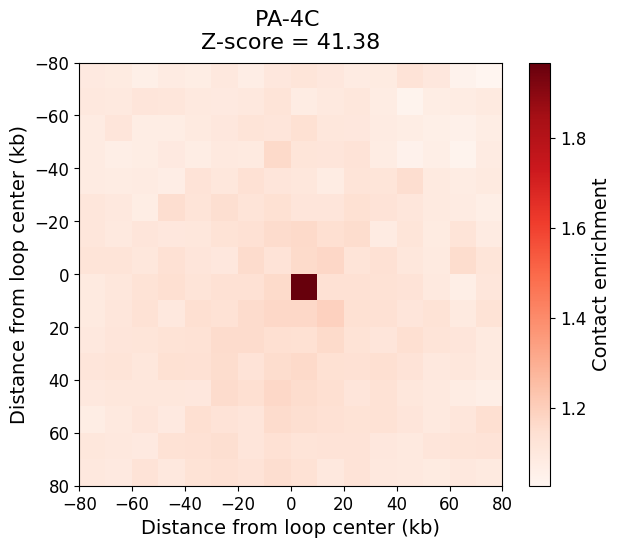

In [61]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C.sub.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig("APA_with_zscore_bigfont.png", dpi=300)
plt.show()

In [127]:
cd /home/lihaoxing/loop_apa/h1_h2_debin_loop_new

/home/lihaoxing/loop_apa/h1_h2_debin_loop_new


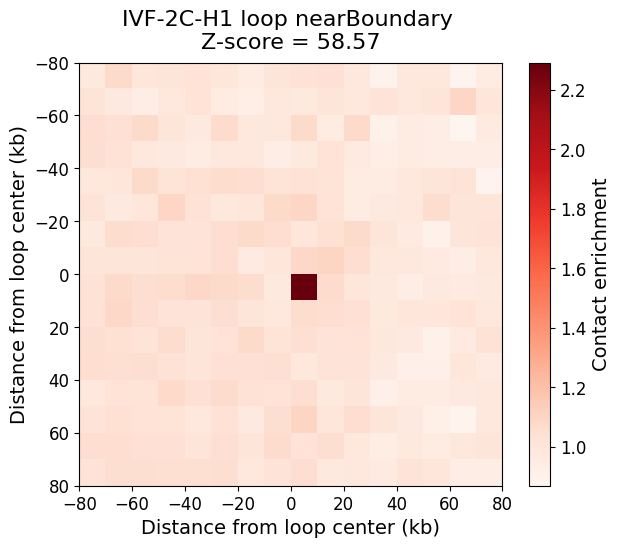

In [128]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C1_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H1 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_2C_H1_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

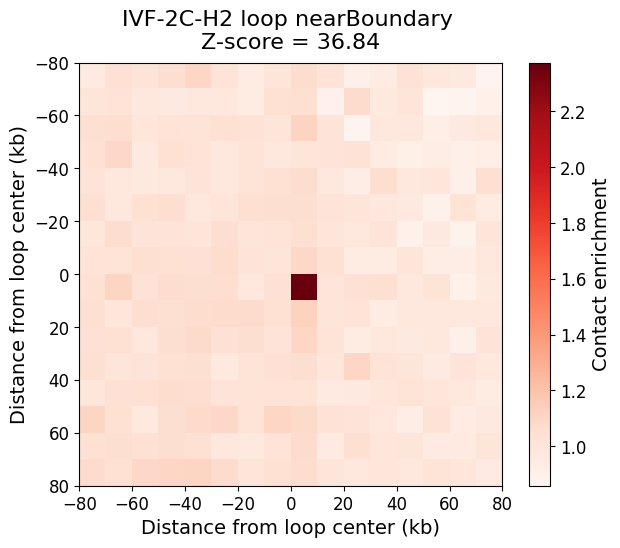

In [129]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C2_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H2 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_2C_H2_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

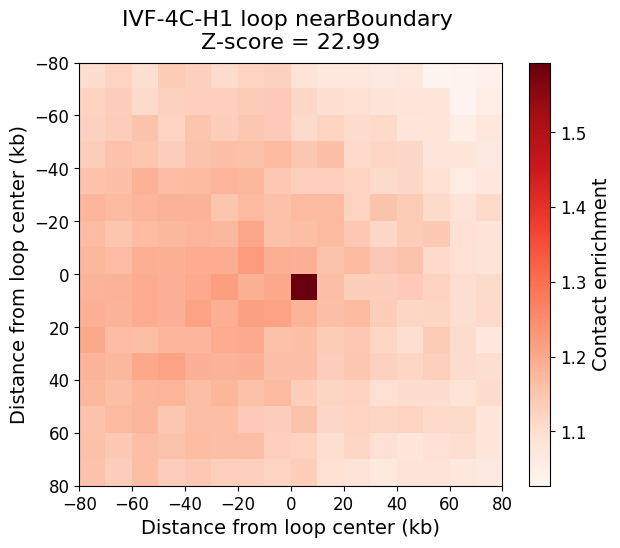

In [130]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C1_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H1 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H1_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

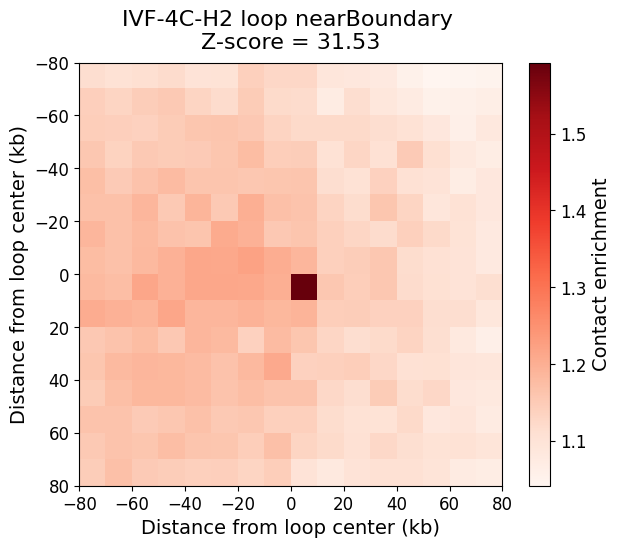

In [131]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C2_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H2 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H2_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

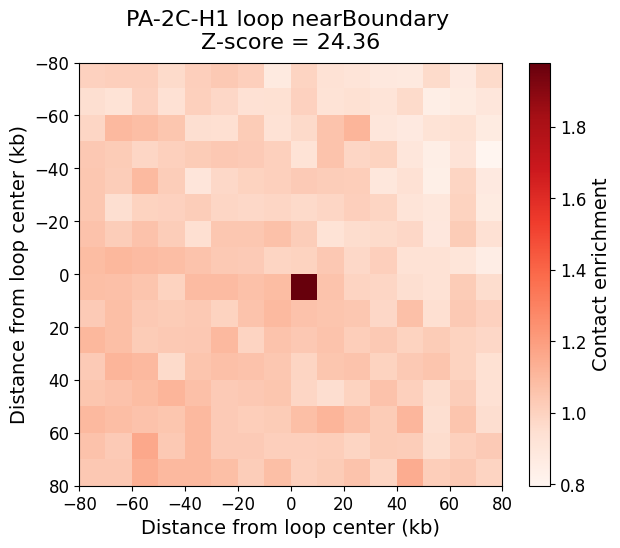

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C1_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H1 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H1_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

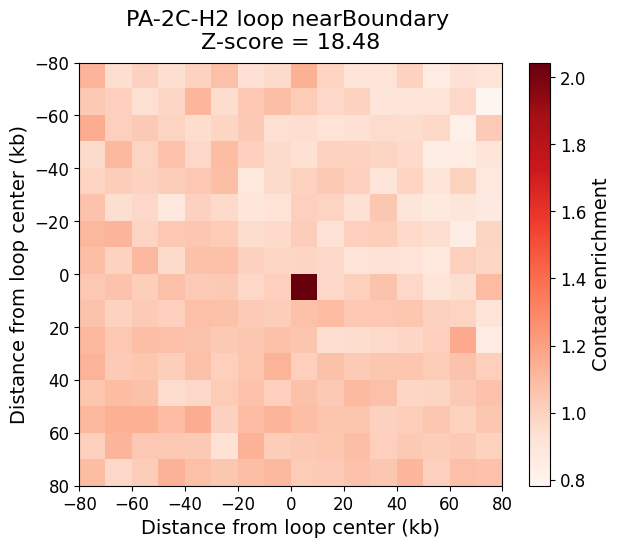

In [133]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C2_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H2 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H2_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

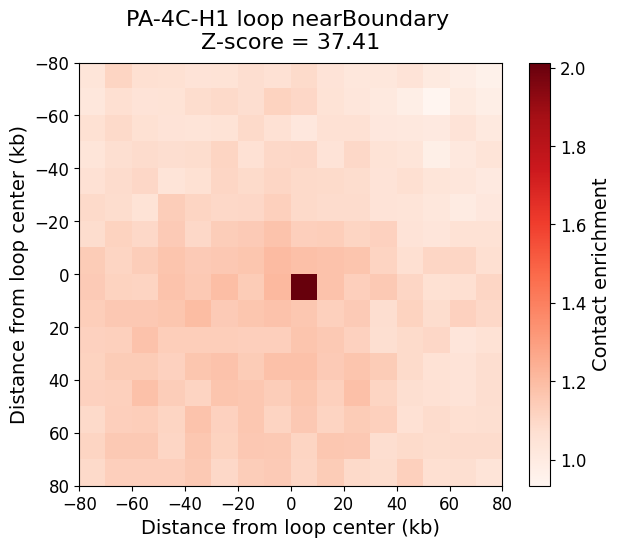

In [134]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C1_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H1 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H1_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

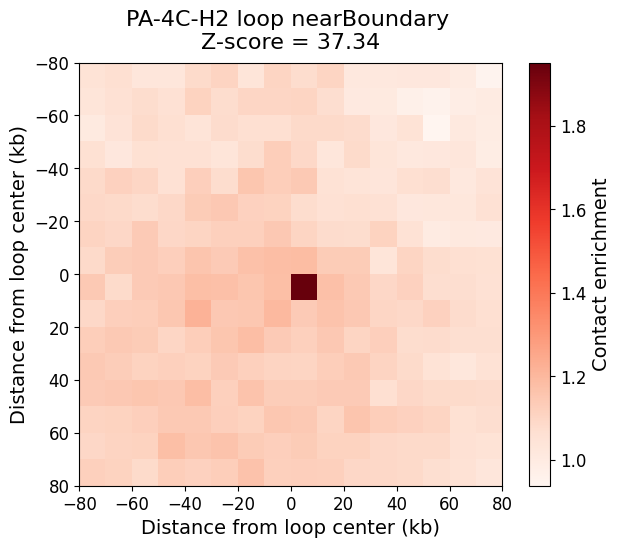

In [135]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C2_loop_nearBoundary.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H2 loop nearBoundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H2_loop_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [2]:
cd /home/lihaoxing/loop_apa/h1_h2_morula_debin_loop_0.925

/home/lihaoxing/loop_apa/h1_h2_morula_debin_loop_0.925


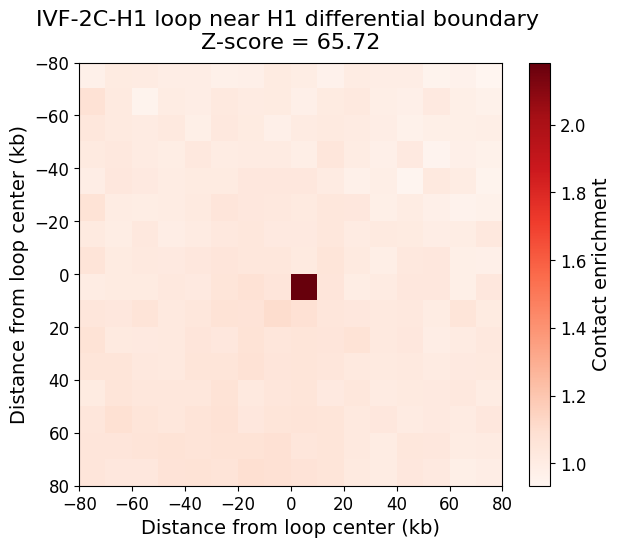

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H1 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

plt.tight_layout()
plt.savefig('IVF_2C_H1_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

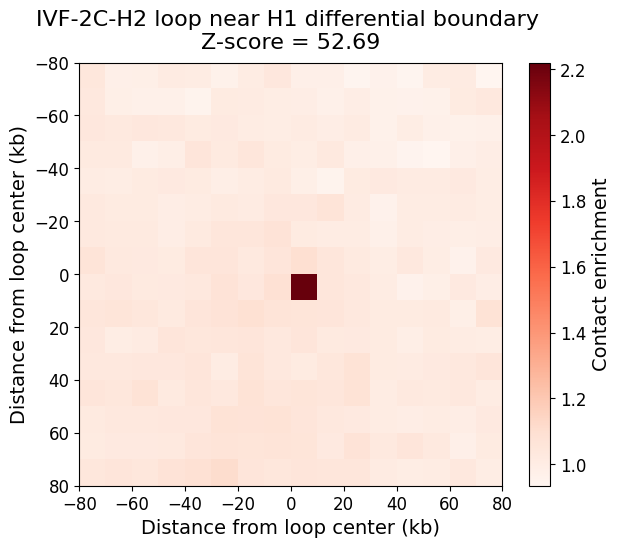

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H2 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

plt.tight_layout()
plt.savefig('IVF_2C_H2_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

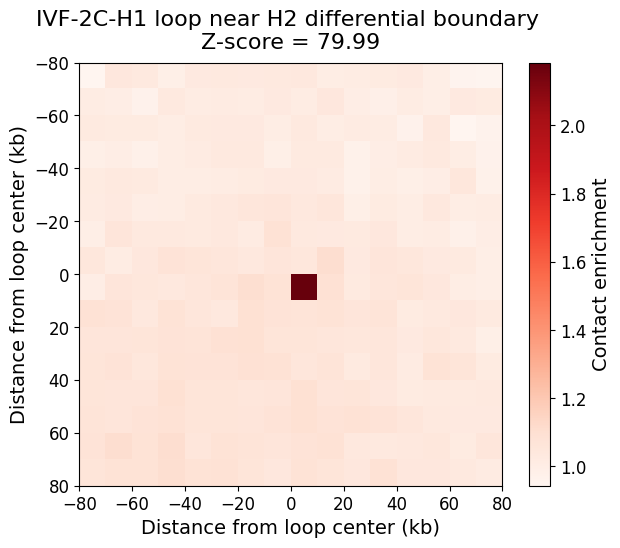

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H1 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_2C_H1_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

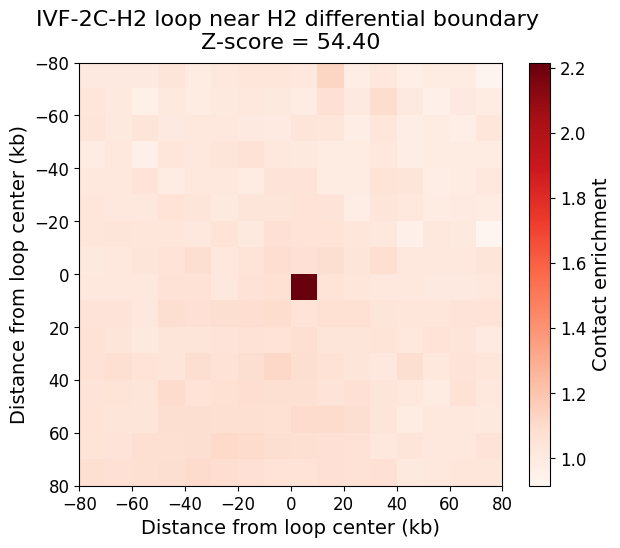

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_2C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-2C-H2 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_2C_H2_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

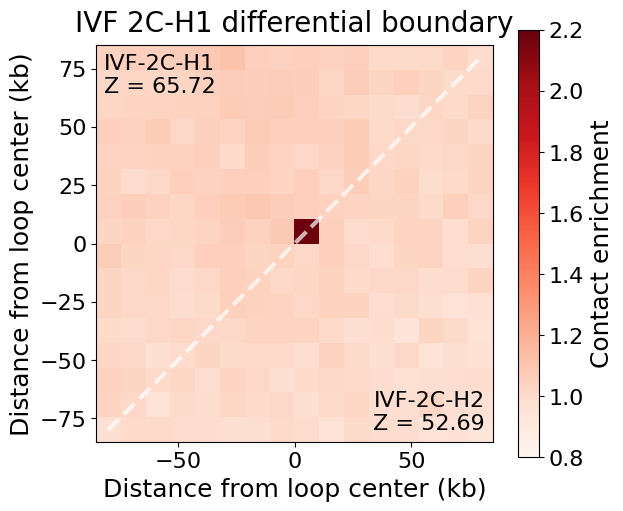

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_2C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
mat_file2 = "IVF_2C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    vmin=0.8,
    vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 2C-H1 differential boundary", fontsize=20, pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-2C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-2C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF2C_H1_H2_inH1.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)

plt.show()

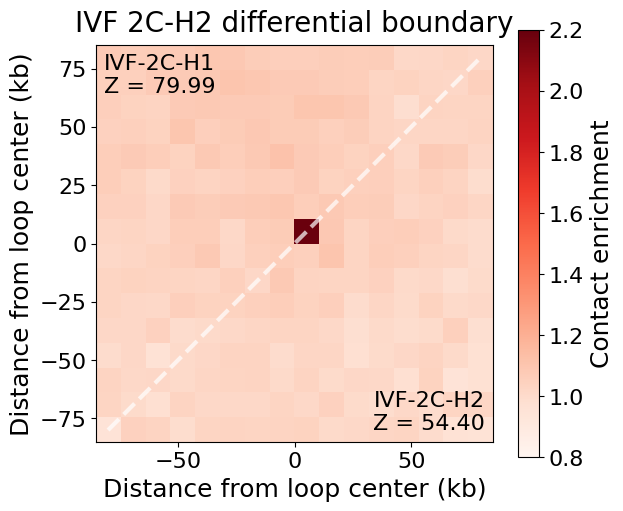

In [15]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_2C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
mat_file2 = "IVF_2C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    vmin=0.8,
    vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 2C-H2 differential boundary", fontsize=20, pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-2C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-2C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF2C_H1_H2_inH2.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

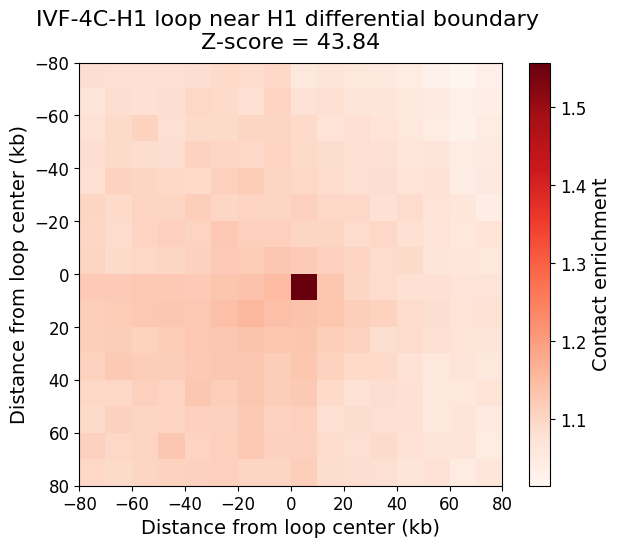

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H1 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H1_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

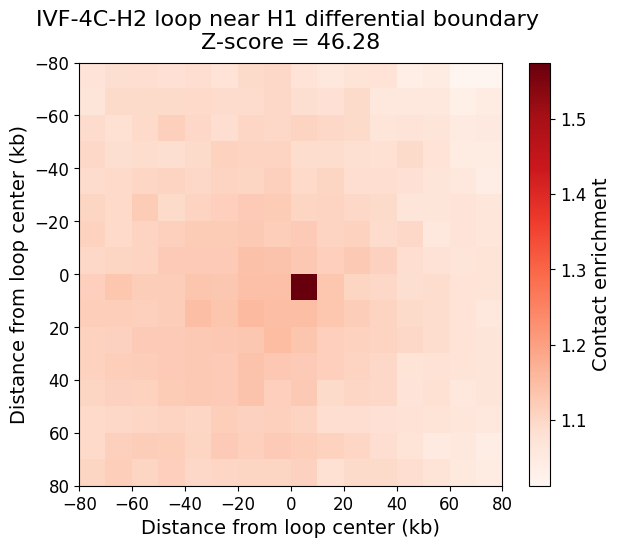

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H2 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H2_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

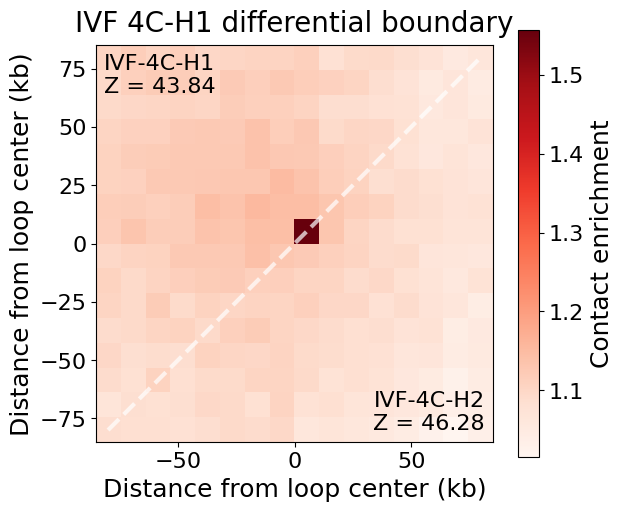

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_4C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
mat_file2 = "IVF_4C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 4C-H1 differential boundary", fontsize=20, pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF4C_H1_H2_inH1.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

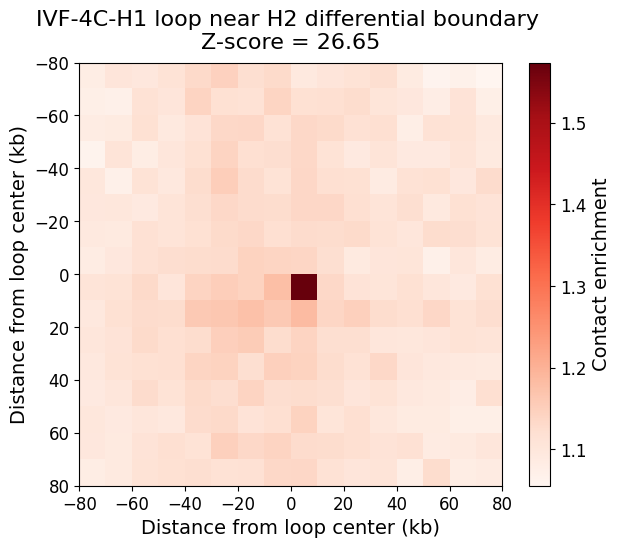

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H1 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H1_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

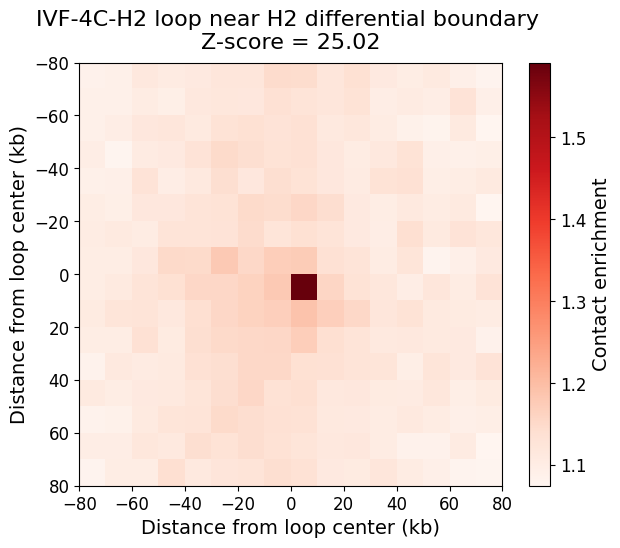

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "IVF_4C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"IVF-4C-H2 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('IVF_4C_H2_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

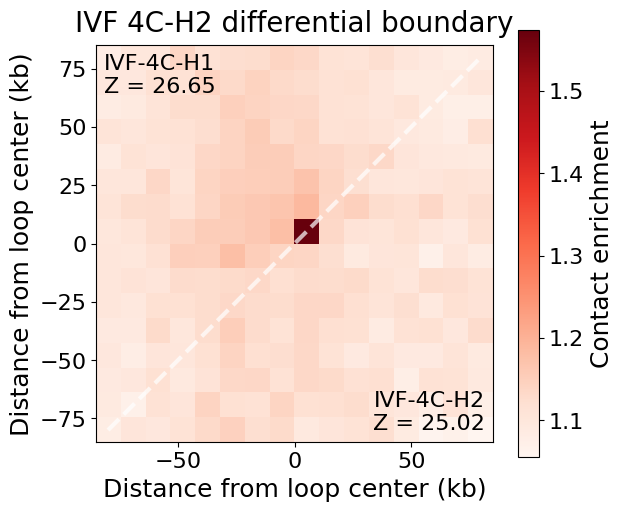

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_4C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
mat_file2 = "IVF_4C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 4C-H2 differential boundary", fontsize=20, pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF4C_H1_H2_inH2.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

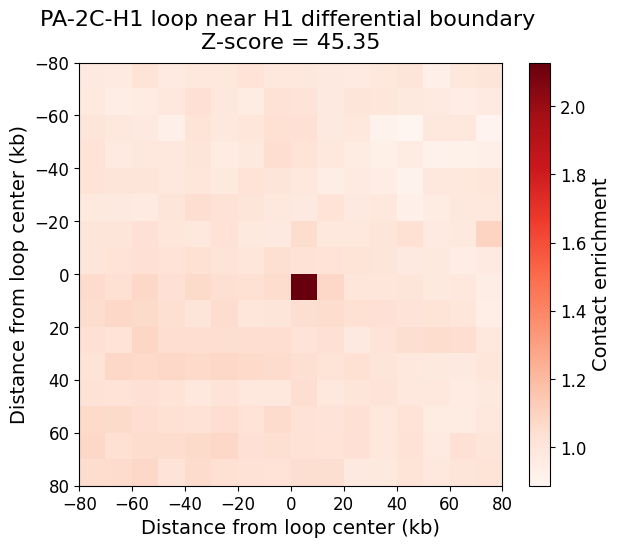

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H1 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H1_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

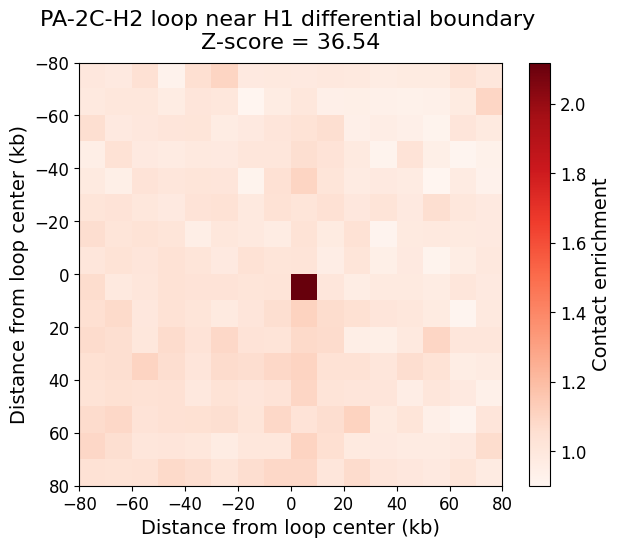

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H2 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H2_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

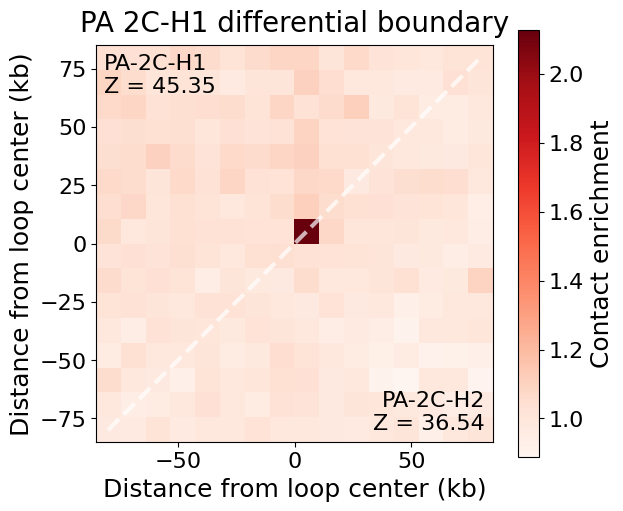

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "PA_2C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
mat_file2 = "PA_2C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("PA 2C-H1 differential boundary", pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"PA-2C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"PA-2C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_PA2C_H1_H2_inH1.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

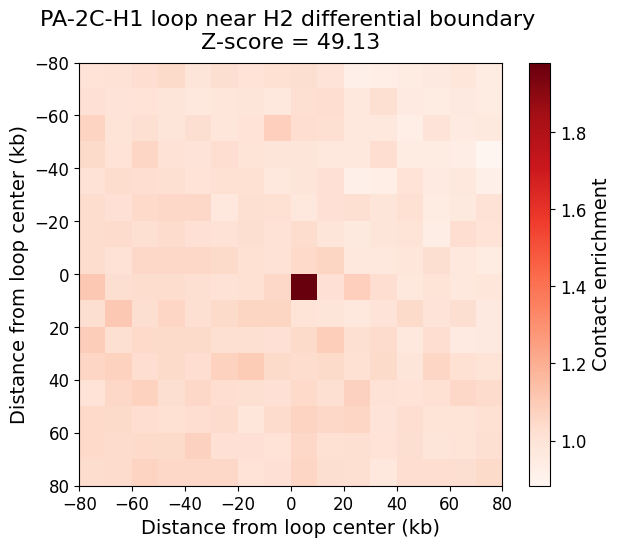

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H1 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H1_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

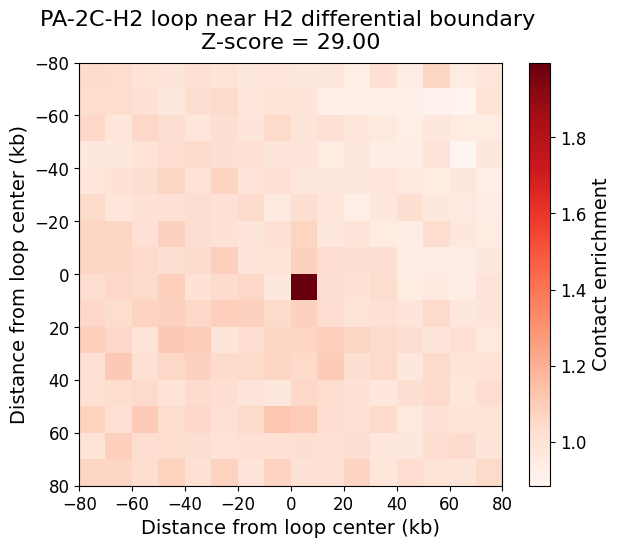

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_2C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-2C-H2 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_2C_H2_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

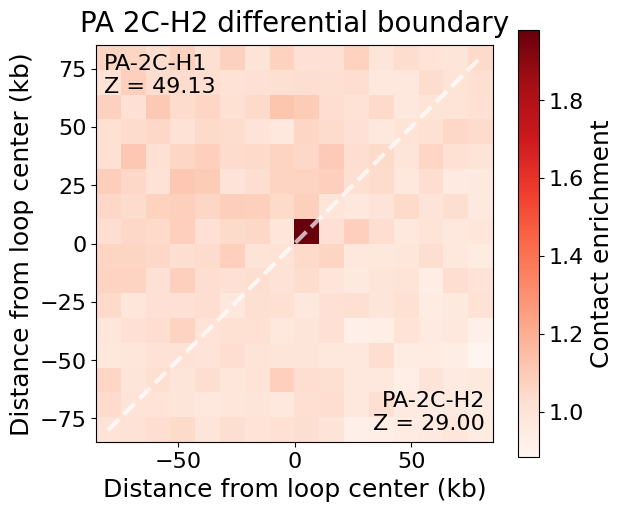

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "PA_2C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
mat_file2 = "PA_2C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("PA 2C-H2 differential boundary", pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"PA-2C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"PA-2C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_PA2C_H1_H2_inH2.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

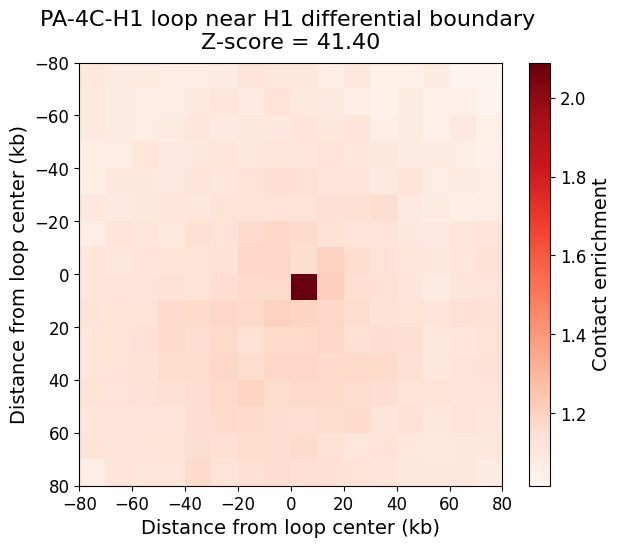

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H1 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H1_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

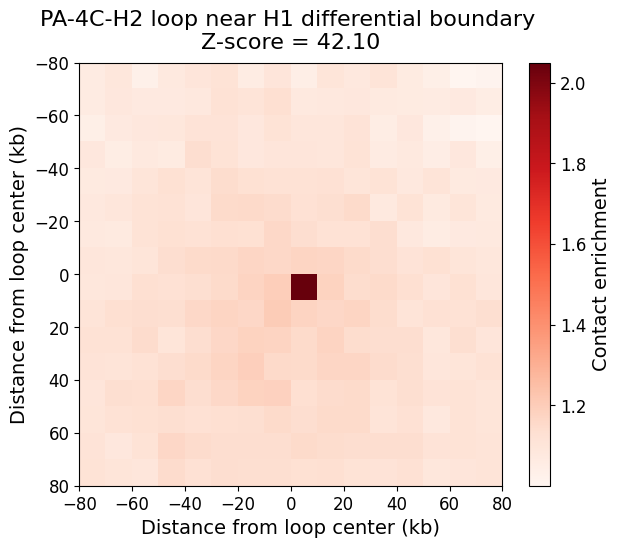

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H2 loop near H1 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H2_loop_H1_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

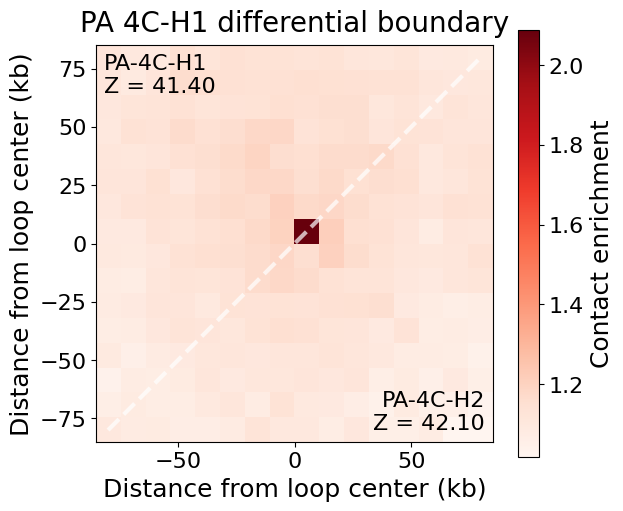

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "PA_4C_C1_norm_cells_no_duplicates_loop_near_H1.agg.matrix"
mat_file2 = "PA_4C_C2_norm_cells_no_duplicates_loop_near_H1.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("PA 4C-H1 differential boundary", pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"PA-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"PA-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_PA4C_H1_H2_inH1.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

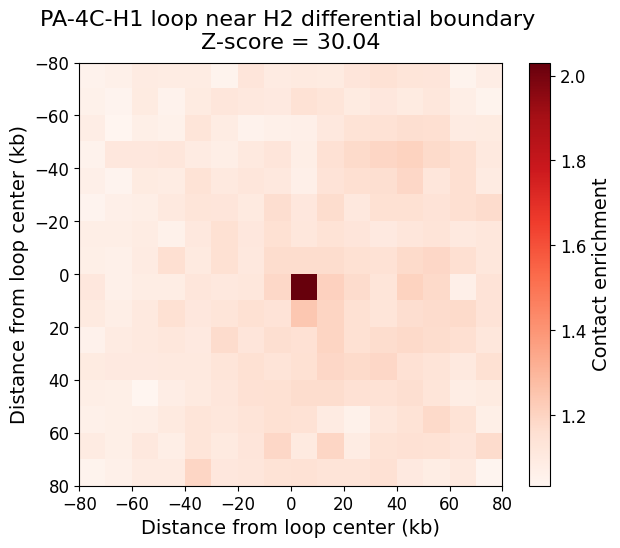

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H1 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H1_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

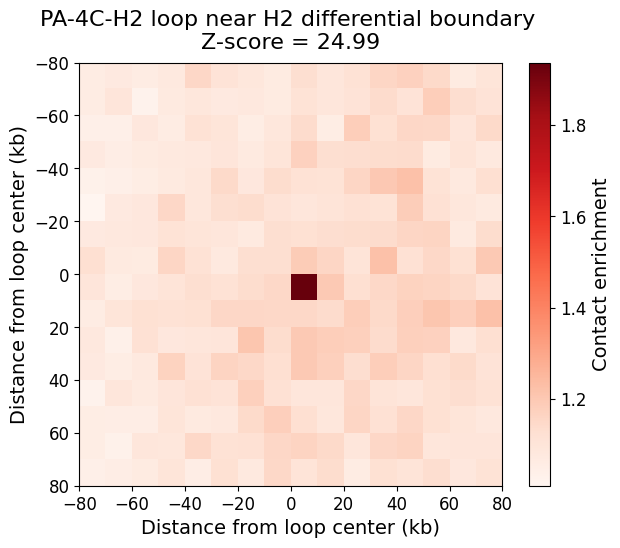

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

mat_file = "PA_4C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
apa = np.loadtxt(mat_file)

bin_size = 10  # kb
window = apa.shape[0] // 2

coords = np.arange(-window, window + 1) * bin_size

bg = apa[-6:, :6]
mu = np.mean(bg)
sigma = np.std(bg)

center = apa[window, window]
z = (center - mu) / sigma

plt.figure(figsize=(6.5,5.5))

im = plt.imshow(
    apa,
    cmap="Reds",
    interpolation="nearest",
    extent=[
        coords[0], coords[-1],
        coords[-1], coords[0]
    ]
)

cbar = plt.colorbar(im)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

plt.xlabel("Distance from loop center (kb)")
plt.ylabel("Distance from loop center (kb)")

plt.title(
    f"PA-4C-H2 loop near H2 differential boundary \nZ-score = {z:.2f}",
    pad=10
)

# ❌ 已删除蓝点

plt.tight_layout()
plt.savefig('PA_4C_H2_loop_H2_nearBoundary.svg', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

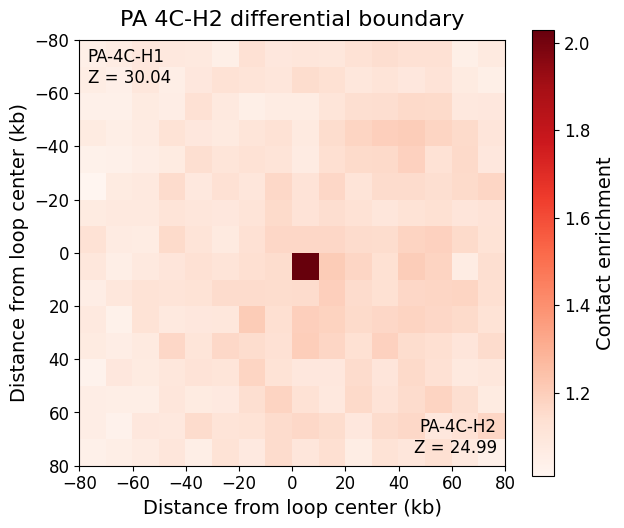

In [40]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 14,
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "figure.titlesize": 16
})

# =============================
# 读取数据
# =============================
mat_file1 = "PA_4C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
mat_file2 = "PA_4C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# =============================
# 双对角线（关键优化）
# =============================

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    extent=[coords[0], coords[-1], coords[-1], coords[0]]
    #vmin=1.0,
    #vmax=2.2
)

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=12)
cbar.set_label("Contact enrichment", fontsize=14)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)")
ax.set_ylabel("Distance from loop center (kb)")
ax.set_title("PA 4C-H2 differential boundary", pad=10)

# =============================
# Z-score（固定在角落，强调样本名）
# =============================
ax.text(0.02, 0.98, f"PA-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=12)

ax.text(0.98, 0.02, f"PA-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=12)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_PA4C_H1_H2_inH2.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)

plt.show()

In [1]:
cd /home/lihaoxing/loop_apa/h1_h2_zga_loop

/home/lihaoxing/loop_apa/h1_h2_zga_loop


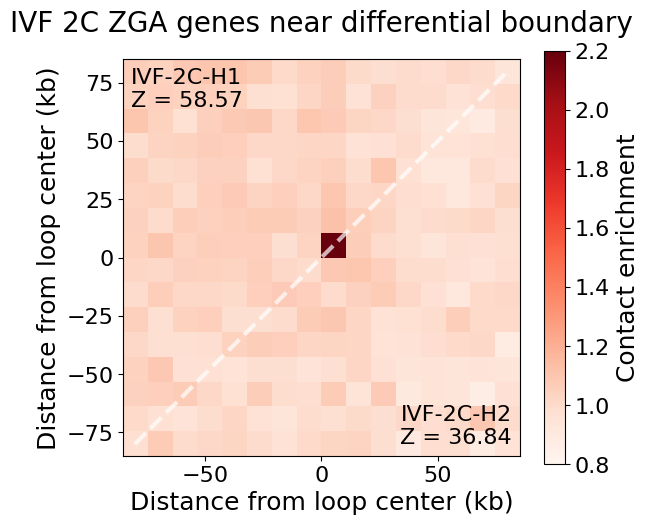

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_2C_C1_ZGA_nearBoundary.agg.matrix"
mat_file2 = "IVF_2C_C2_ZGA_nearBoundary.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    vmin=0.8,
    vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 2C ZGA genes near differential boundary", fontsize=20, pad=20)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-2C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-2C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF2C_H1_H2_ZGA_nearBoundary.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)

plt.show()

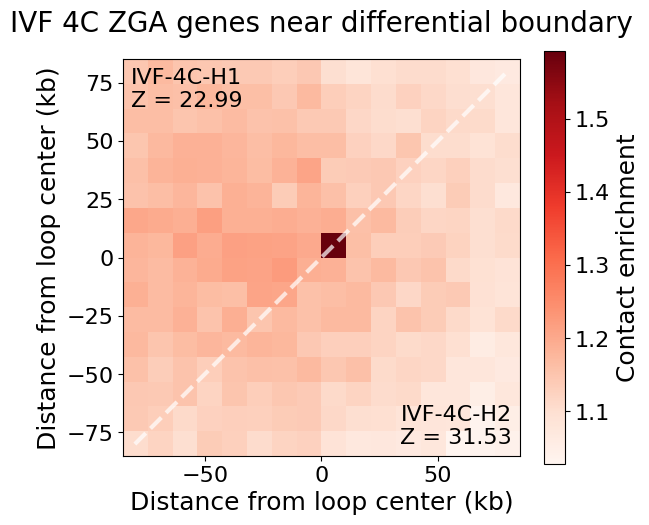

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "IVF_4C_C1_ZGA_nearBoundary.agg.matrix"
mat_file2 = "IVF_4C_C2_ZGA_nearBoundary.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("IVF 4C ZGA genes near differential boundary", fontsize=20, pad=20)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"IVF-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"IVF-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_IVF4C_H1_H2_ZGA_nearBoundary.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)

plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ========== 字体放大 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "figure.titlesize": 18
})

# =============================
# 读取数据
# =============================
mat_file1 = "PA_4C_C1_norm_cells_no_duplicates_loop_near_H2.agg.matrix"
mat_file2 = "PA_4C_C2_norm_cells_no_duplicates_loop_near_H2.agg.matrix"

apa1 = np.loadtxt(mat_file1)
apa2 = np.loadtxt(mat_file2)

assert apa1.shape == apa2.shape, "Matrix shapes differ"
n = apa1.shape[0]

# =============================
# Z-score
# =============================
def calc_zscore(apa):
    bg = apa[-6:, :6]
    mu = np.mean(bg)
    sigma = np.std(bg)
    center = apa[n//2, n//2]
    return (center - mu) / sigma

z1 = calc_zscore(apa1)
z2 = calc_zscore(apa2)

# =============================
# 拼接矩阵（核心逻辑）
# =============================
combined = np.zeros_like(apa1)

# 上三角：H1
upper_mask = np.triu(np.ones_like(apa1, dtype=bool), k=1)
combined[upper_mask] = apa1[upper_mask]

# 下三角：H2
lower_mask = np.tril(np.ones_like(apa1, dtype=bool), k=-1)
combined[lower_mask] = apa2[lower_mask]

# 主对角线：H1
np.fill_diagonal(combined, np.diag(apa1))

# 次对角线（下方一格）：H2
for i in range(n - 1):
    combined[i+1, i] = apa2[i+1, i]

# =============================
# 坐标（像素中心）
# =============================
bin_size = 10
window = n // 2
coords = np.arange(-window, window + 1) * bin_size
half = bin_size / 2.0

# =============================
# 画图
# =============================
fig, ax = plt.subplots(figsize=(6.5, 5.5))

# ---------- 修正 extent：像素边缘，确保中心像素对齐 ----------
im = ax.imshow(
    combined,
    cmap="Reds",
    interpolation="nearest",
    origin='lower',  # 数据坐标 y 轴从下到上递增
    extent=[coords[0] - half, coords[-1] + half,
            coords[0] - half, coords[-1] + half],
    #vmin=0.8,
    #vmax=2.2
)

# ========== 对称轴：y = x（从左下到右上） ==========
ax.plot([coords[0], coords[-1]], [coords[0], coords[-1]],
        color='white', linestyle='--', linewidth=3, alpha=0.7,
        label='Symmetry axis (y=x)')

# colorbar
cbar = plt.colorbar(im, ax=ax)
cbar.ax.tick_params(labelsize=16)
cbar.set_label("Contact enrichment", fontsize=18)

# =============================
# 坐标轴
# =============================
ax.set_xlabel("Distance from loop center (kb)", fontsize=18)
ax.set_ylabel("Distance from loop center (kb)", fontsize=18)
ax.set_title("PA 4C-H2 differential boundary", pad=10)

# =============================
# Z-score（固定在角落）
# =============================
ax.text(0.02, 0.98, f"PA-4C-H1\nZ = {z1:.2f}",
        transform=ax.transAxes,
        ha='left', va='top',
        fontsize=16)

ax.text(0.98, 0.02, f"PA-4C-H2\nZ = {z2:.2f}",
        transform=ax.transAxes,
        ha='right', va='bottom',
        fontsize=16)

# =============================
# 输出
# =============================
plt.tight_layout()
plt.savefig('Combined_APA_PA4C_H1_H2_inH2.svg',
            dpi=300,
            bbox_inches='tight',
            transparent=True)


plt.show()

In [19]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix

/home/lihaoxing/loop_apa_0.925/single_cell/ivf_pa_2cluster/matrix


In [ ]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("APA_zscore_summary.txt", sep="\t", index=False)

4-100-3.csv.0.925_c1.bedpe.agg.matrix 20.85264810986944
IVF-4-70-3.csv.0.925_c0.bedpe.agg.matrix 20.34502605102429
2-41-2.csv.0.925_c0.bedpe.agg.matrix 26.17300230410107
IVF-2-150-1.csv.0.925_c0.bedpe.agg.matrix 33.73246305233731
IVF-4-71-3.csv.0.925_c1.bedpe.agg.matrix 17.744999342730924
IVF-4-70-3.csv.0.925_c1.bedpe.agg.matrix 19.062753590148954
4-38-1.csv.0.925_c1.bedpe.agg.matrix 16.077671383641917
NPB-41-1.csv.0.925_c1.bedpe.agg.matrix 3.8396302839575776
NPB-34-1.csv.0.925_c0.bedpe.agg.matrix 28.992268607911416
G4-3-3.csv.0.925_c0.bedpe.agg.matrix 2.128703892675704
2-45-2.csv.0.925_c0.bedpe.agg.matrix 6.6828755887842775
2-114-2.csv.0.925_c1.bedpe.agg.matrix 30.692719870815562
IVF-4-78-3.csv.0.925_c1.bedpe.agg.matrix 19.850174101787804
IVF-4-37-1.csv.0.925_c0.bedpe.agg.matrix 19.21947651445424
4-221-3.csv.0.925_c0.bedpe.agg.matrix 8.4973941037223
IVF-2-53-1.csv.0.925_c1.bedpe.agg.matrix 10.49005986824456
PB-11-1.csv.0.925_c0.bedpe.agg.matrix 11.385641434997856
2-43-2.csv.0.925_c1.b

In [51]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/all_genes_loopAPA

/home/lihaoxing/loop_apa_0.925/single_cell/all_genes_loopAPA


In [53]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("allgenes_APA_zscore_summary.txt", sep="\t", index=False)

IVF-4-72-2.csv.0.925.bedpe.agg.matrix 25.27199728589127
IVF-4-86-1.csv.0.925.bedpe.agg.matrix 18.15316436979343
IVF-2-13-1.csv.0.925.bedpe.agg.matrix 40.771336144201086
4-100-1.csv.0.925.bedpe.agg.matrix 32.72822179439444
G4-10-1.csv.0.925.bedpe.agg.matrix 23.454015656761847
4-253-3.csv.0.925.bedpe.agg.matrix 16.86647094633533
IVF-2-49-2.csv.0.925.bedpe.agg.matrix 39.06741551120428
IVF-4-121-1.csv.0.925.bedpe.agg.matrix 23.824122391370988
IVF-4-55-3.csv.0.925.bedpe.agg.matrix 23.943778773472967
2-115-2.csv.0.925.bedpe.agg.matrix 38.58473890512965
IVF-4-47-2.csv.0.925.bedpe.agg.matrix 22.4838053473349
IVF-4-9-4.csv.0.925.bedpe.agg.matrix 18.226064540354397
2-45-2.csv.0.925.bedpe.agg.matrix 9.474205642096392
4-71-2.csv.0.925.bedpe.agg.matrix 15.577460025199565
2-67-1.csv.0.925.bedpe.agg.matrix 46.02535431657652
IVF-4-99-3.csv.0.925.bedpe.agg.matrix 35.73351283568314
G4-1-4.csv.0.925.bedpe.agg.matrix 10.533182631561376
IVF-2-114-2.csv.0.925.bedpe.agg.matrix 29.701953528996636
4-52-1.csv.0

4-81-1.csv.0.925.bedpe.agg.matrix 5.6695339429648515
IVF-4-18-3.csv.0.925.bedpe.agg.matrix 25.212616312001067
IVF-4-80-4.csv.0.925.bedpe.agg.matrix 21.539861417892
2-117-1.csv.0.925.bedpe.agg.matrix 9.474205642096392
IVF-4-79-3.csv.0.925.bedpe.agg.matrix 11.912154790163878
4-252-4.csv.0.925.bedpe.agg.matrix 29.746512965461346
IVF-2-20-2.csv.0.925.bedpe.agg.matrix 47.47154780373141
G4-8-4.csv.0.925.bedpe.agg.matrix 5.919101056584452
IVF-4-49-2.csv.0.925.bedpe.agg.matrix 18.510550000989973
IVF-4-55-4.csv.0.925.bedpe.agg.matrix 22.08265343479596
2-10-1.csv.0.925.bedpe.agg.matrix 37.33993103110629
4-195-2.csv.0.925.bedpe.agg.matrix 21.50841901275615
2-118-1.csv.0.925.bedpe.agg.matrix 40.41848269638967
4-260-3.csv.0.925.bedpe.agg.matrix 1.749141412439299
G4-10-2.csv.0.925.bedpe.agg.matrix 24.832280785696693
IVF-2-23-1.csv.0.925.bedpe.agg.matrix 49.9261286953019
2-126-2.csv.0.925.bedpe.agg.matrix 32.51064315482377
IVF-2-145-1.csv.0.925.bedpe.agg.matrix 40.786128006925274
2-46-1.csv.0.925.bed

In [54]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/IVF_2C_3class

/home/lihaoxing/loop_apa_0.925/single_cell/IVF_2C_3class


In [55]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("IVF_2C_3class_APA_zscore_summary.txt", sep="\t", index=False)

IVF-2-113-2.csv.0.925_other.bedpe.agg.matrix 27.291991460548335
IVF-2-146-2.csv.0.925_other.bedpe.agg.matrix 34.783014772831024
IVF-2-168-1.csv.0.925_ZGA.bedpe.agg.matrix 7.3666742240294525
IVF-2-101-1.csv.0.925_other.bedpe.agg.matrix 32.63913538743944
IVF-2-169-2.csv.0.925_ZGA.bedpe.agg.matrix 16.592368455356784
IVF-2-157-1.csv.0.925_other.bedpe.agg.matrix 30.22209695805594
IVF-2-152-1.csv.0.925_other.bedpe.agg.matrix 32.79810504361151
IVF-2-114-2.csv.0.925_other.bedpe.agg.matrix 27.132571362907484
IVF-2-27-1.csv.0.925_ZGA.bedpe.agg.matrix 18.995998638286846
IVF-2-162-1.csv.0.925_other.bedpe.agg.matrix 29.111798645391605
IVF-2-115-2.csv.0.925_ZGA.bedpe.agg.matrix 1.9313215158356338
IVF-2-42-2.csv.0.925_MD.bedpe.agg.matrix 9.978115483118305
IVF-2-23-1.csv.0.925_MD.bedpe.agg.matrix 18.280853009088744
IVF-2-48-2.csv.0.925_ZGA.bedpe.agg.matrix 12.82749801279589
IVF-2-157-1.csv.0.925_ZGA.bedpe.agg.matrix 12.059492667124184
IVF-2-47-1.csv.0.925_other.bedpe.agg.matrix 40.573878864622316
IVF-

In [56]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/IVF_4C_3class

/home/lihaoxing/loop_apa_0.925/single_cell/IVF_4C_3class


In [57]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("IVF_4C_3class_APA_zscore_summary.txt", sep="\t", index=False)

IVF-4-31-4.csv.0.925_other.bedpe.agg.matrix 17.8681720883589
IVF-4-102-2.csv.0.925_other.bedpe.agg.matrix 19.361928477277164
IVF-4-118-3.csv.0.925_other.bedpe.agg.matrix 16.94877154979222
IVF-4-73-1.csv.0.925_ZGA.bedpe.agg.matrix 16.33221261884965
IVF-4-18-1.csv.0.925_other.bedpe.agg.matrix 17.994549971022618
IVF-4-99-3.csv.0.925_MD.bedpe.agg.matrix 10.684524255956427
IVF-4-87-2.csv.0.925_other.bedpe.agg.matrix 14.802560606156167
IVF-4-4-1.csv.0.925_MD.bedpe.agg.matrix 8.272351592547837
IVF-4-95-1.csv.0.925_MD.bedpe.agg.matrix 11.048788096699024
IVF-4-121-3.csv.0.925_MD.bedpe.agg.matrix 8.024000035010591
IVF-4-99-3.csv.0.925_other.bedpe.agg.matrix 24.836013855429336
IVF-4-78-3.csv.0.925_MD.bedpe.agg.matrix 7.903175656056712
IVF-4-85-4.csv.0.925_other.bedpe.agg.matrix 19.901799356614838
IVF-4-43-2.csv.0.925_MD.bedpe.agg.matrix 8.904535112768452
IVF-4-2-1.csv.0.925_MD.bedpe.agg.matrix 2.1753196972315627
IVF-4-87-1.csv.0.925_other.bedpe.agg.matrix 22.208134050755987
IVF-4-84-2.csv.0.925_M

In [58]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/PA_2C_3class

/home/lihaoxing/loop_apa_0.925/single_cell/PA_2C_3class


In [59]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("PA_2C_3class_APA_zscore_summary.txt", sep="\t", index=False)

NPB-29-1.csv.0.925_MD.bedpe.agg.matrix 2.448577144785549
2-17-1.csv.0.925_MD.bedpe.agg.matrix 9.665081368750112
2-130-1.csv.0.925_MD.bedpe.agg.matrix 22.093718719878588
NPB-20-1.csv.0.925_ZGA.bedpe.agg.matrix 14.341031878283095
2-31-2.csv.0.925_MD.bedpe.agg.matrix 14.675536786179261
2-46-2.csv.0.925_ZGA.bedpe.agg.matrix 24.060946780520084
2-129-1.csv.0.925_ZGA.bedpe.agg.matrix 16.15475499079102
2-65-1.csv.0.925_other.bedpe.agg.matrix 27.40093286718297
2-110-1.csv.0.925_MD.bedpe.agg.matrix 11.028509915563363
2-60-1.csv.0.925_ZGA.bedpe.agg.matrix 15.264940952622855
2-36-1.csv.0.925_other.bedpe.agg.matrix 37.06026490304464
PB-6-2.csv.0.925_ZGA.bedpe.agg.matrix 13.466084653652771
2-33-2.csv.0.925_ZGA.bedpe.agg.matrix 8.470448961199075
2-26-2.csv.0.925_other.bedpe.agg.matrix 41.79233873427209
2-73-1.csv.0.925_MD.bedpe.agg.matrix 7.76683667462628
2-109-2.csv.0.925_MD.bedpe.agg.matrix 2.448577144785549
2-120-1.csv.0.925_MD.bedpe.agg.matrix 11.370022317736153
2-16-1.csv.0.925_MD.bedpe.agg.matr

In [60]:
cd /home/lihaoxing/loop_apa_0.925/single_cell/PA_4C_3class

/home/lihaoxing/loop_apa_0.925/single_cell/PA_4C_3class


In [61]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("PA_4C_3class_APA_zscore_summary.txt", sep="\t", index=False)

4-237-1.csv.0.925_ZGA.bedpe.agg.matrix 21.819396715492243
D4-7-4.csv.0.925_other.bedpe.agg.matrix 1.6895422845253798
4-130-3.csv.0.925_other.bedpe.agg.matrix 14.22787967303974
4-14-1.csv.0.925_MD.bedpe.agg.matrix 2.0668146864873855
4-2-1.csv.0.925_ZGA.bedpe.agg.matrix 0.6443022261368624
4-271-1.csv.0.925_ZGA.bedpe.agg.matrix 23.46148752523868
4-48-2.csv.0.925_ZGA.bedpe.agg.matrix 15.605418241527047
G4-2-3.csv.0.925_other.bedpe.agg.matrix 25.984761870801414
4-104-3.csv.0.925_other.bedpe.agg.matrix 29.36334576544873
G4-5-3.csv.0.925_MD.bedpe.agg.matrix 10.436693656305653
4-141-1.csv.0.925_ZGA.bedpe.agg.matrix 6.788877137563398
4-195-2.csv.0.925_MD.bedpe.agg.matrix 13.898121635224744
G4-3-2.csv.0.925_MD.bedpe.agg.matrix 2.6808886158050993
Y4-4-1.csv.0.925_other.bedpe.agg.matrix 17.163673140293305
4-100-3.csv.0.925_other.bedpe.agg.matrix 26.398279807097605
4-15-1.csv.0.925_MD.bedpe.agg.matrix 1.3482201422847104
4-167-4.csv.0.925_other.bedpe.agg.matrix 4.990724409401119
4-97-1.csv.0.925_ZGA

D4-51-3.csv.0.925_MD.bedpe.agg.matrix 12.22061686062319
D4-26-2.csv.0.925_ZGA.bedpe.agg.matrix 2.736781157212504
4-237-1.csv.0.925_other.bedpe.agg.matrix 23.706096865547362
4-255-1.csv.0.925_ZGA.bedpe.agg.matrix -0.11366988473509451
4-197-3.csv.0.925_MD.bedpe.agg.matrix 16.182292079406395
4-262-2.csv.0.925_other.bedpe.agg.matrix 3.8734699874378524
G4-59-3.csv.0.925_ZGA.bedpe.agg.matrix 13.512130448641146
4-281-2.csv.0.925_ZGA.bedpe.agg.matrix 5.877557080362299
D4-51-1.csv.0.925_other.bedpe.agg.matrix 20.69152179928115
4-270-4.csv.0.925_ZGA.bedpe.agg.matrix 15.687372275428556
4-260-2.csv.0.925_MD.bedpe.agg.matrix -0.5862917779339216
4-71-4.csv.0.925_MD.bedpe.agg.matrix 3.2350359116242307


In [62]:
cd /home/lihaoxing/out

/home/lihaoxing/out


In [63]:
import numpy as np
import os
import pandas as pd

mat_files = [f for f in os.listdir() if f.endswith(".matrix")]

results = []

for mat_file in mat_files:
    try:
        apa = np.loadtxt(mat_file)

        # window center
        window = apa.shape[0] // 2

        # background (same as your code)
        bg = apa[-6:, :6]
        mu = np.mean(bg)
        sigma = np.std(bg)

        center = apa[window, window]

        # 防止除0
        if sigma == 0:
            z = np.nan
        else:
            z = (center - mu) / sigma

        results.append([mat_file, z])

        print(mat_file, z)

    except Exception as e:
        print(f"Error processing {mat_file}: {e}")

# =========================
# 输出结果
# =========================
df = pd.DataFrame(results, columns=["file", "z_score"])
df.to_csv("xxx.txt", sep="\t", index=False)

IVF-2-152-1.csv.0.925_ENSSSCG00000030428.bedpe.agg.matrix 0.8198198189362823
IVF-2-152-1.csv.0.925_ENSSSCG00000030432.bedpe.agg.matrix 0.47253892494377964
IVF-2-152-1.csv.0.925_ENSSSCG00000030420.bedpe.agg.matrix 1.6085041143285337
IVF-2-152-1.csv.0.925_ENSSSCG00000029590.bedpe.agg.matrix -1.124743882240119
IVF-2-152-1.csv.0.925_ENSSSCG00000030546.bedpe.agg.matrix -0.7394846559899177
IVF-2-152-1.csv.0.925_ENSSSCG00000029865.bedpe.agg.matrix 5.242470553947015
